# Who Will Give Next Year? A Cost-Based Model for Mail vs. Email

**Goal:** predict which past donors will make a gift in the next fiscal year, so the annual giving team knows who to solicit.

**Why recall comes first.** In fundraising the two kinds of mistakes don't cost the same:

| Mistake | What it costs |
|---|---|
| Solicit someone who doesn't give (false positive) | About $0.70 for a mail piece, a few cents for an email |
| Skip someone who would have given (false negative) | Their whole gift (median around $50–$100), and possibly the relationship |

So instead of a 50/50 cutoff, the model uses a **cost cutoff**: solicit a donor whenever the gift we expect from them is worth more than what it costs to ask.

> Solicit if **probability of giving × expected gift > cost of soliciting them for a year**

**Below the cutoff doesn't mean dropped.** The cutoff decides who gets the more expensive channel, direct mail. Everyone else stays on the email list (if we have a usable address), because email costs about a penny per send. Mail only goes to donors who are actually mailable: a usable mailing address and no Do Not Mail code. The model moves people between channels; it never removes anyone from the program.

A donor with a 5% chance of giving $60 is worth $3 in expectation. If mailing them all year costs $2.60, they make the list. Because asking is cheap and gifts are not, this rule naturally favors finding givers over keeping the list small.

**Setup (from `README_generatedata.md`):** one row per donor per fiscal year, for everyone who has ever given. Target = did they give the *following* year.
Train on FY2022→23, FY2023→24, FY2024→25. Test on FY2025→26, a year the model never sees.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, recall_score,
                             precision_score, confusion_matrix)

pd.set_option("display.float_format", "{:,.3f}".format)

# The CSVs that generate_data.py writes - saved in the data folder
summary = pd.read_csv("data/donor_fy_summary.csv")
donors = pd.read_csv("data/donors.csv", parse_dates=["record_created_date"])
gifts = pd.read_csv("data/gifts.csv", parse_dates=["gift_date"])
sols = pd.read_csv("data/solicitations.csv")

COST_PER_PIECE = 0.70   # README_generatedata.md: $0.60-$0.75 to print and mail one more piece

## 1. Rebuild contact info *as of each year*

`donors.csv` shows contact info as of the end of FY2026. If we used it as-is, a donor whose email bounced in FY2025 would look like they had no email back in FY2022. That's **leakage**: the model would be using information from the future.

The fix: solicitations.csv records every bounce, returned mailing, wrong number, and unsubscribe. If a donor lost their address in FY2025, then they still had it at the end of FY2022, 2023, and 2024.

**Solicit codes get the same treatment.** `donors.csv` only has each donor's final Do Not Mail, Do Not Call, and One Solicitation Per Year codes, with no record of when they were added. But the solicitations table shows what each donor was actually sent, and a code can't have been in effect in a year the donor was asked in a way it forbids:
- **Do Not Mail:** not in effect in any year the donor received direct mail.
- **Do Not Call:** not in effect in any year the donor was phoned.
- **One Solicitation Per Year:** not in effect in any year the donor got more than one ask.

So each code is treated as starting the year after the last ask that contradicts it. A donor with a code and no contradicting asks is treated as having it the whole time. Because `donors.csv` is the record at the end of FY2026, every code listed there was in place by the end of FY2026. This assumes codes are added and not later removed.


In [2]:
sols["fiscal_year"] = 2000 + sols["appeal_id"].str[2:4].astype(int)
sols["channel"] = sols["appeal_id"].str[5:7]          # DM, EM, PO

def first_year(mask):
    """First fiscal year each donor had this event."""
    return sols[mask].groupby("donor_id")["fiscal_year"].min()

def last_year(mask):
    """Last fiscal year each donor had this event."""
    return sols[mask].groupby("donor_id")["fiscal_year"].max()

bad = sols["bad_contact_info"] == 1
lost = pd.DataFrame({
    "address_lost_fy": first_year(bad & (sols.channel == "DM")),
    "email_lost_fy":   first_year(bad & ((sols.channel == "EM") | (sols.contact_method == "Personal Email"))),
    "phone_lost_fy":   first_year(bad & (sols.contact_method == "Phone")),
    "unsub_fy":        first_year(sols["unsubscribed"] == 1),
})
# Solicit codes: each starts the year after the last ask it would have blocked.
# Capped at FY2026, since donors.csv shows the codes as of the end of FY2026.
asks_per_year = sols.groupby(["donor_id", "fiscal_year"]).size()
multi_ask_years = asks_per_year[asks_per_year > 1].reset_index()
code_start = pd.DataFrame({
    "dnm_start_fy":     last_year(sols.channel == "DM") + 1,
    "dnc_start_fy":     last_year(sols.contact_method == "Phone") + 1,
    "one_sol_start_fy": multi_ask_years.groupby("donor_id")["fiscal_year"].max() + 1,
}).clip(upper=2026)

contact = donors.set_index("donor_id")[["has_mailing_address", "has_email", "has_phone",
                                        "do_not_mail", "do_not_call", "do_not_email",
                                        "one_solicitation_per_year"]].join(lost).join(code_start)

def as_of(final_flag, change_fy, fy, turns_on=False):
    """Value of a flag at the end of `fy`, given its final value and the year it changed."""
    changed_later = change_fy.notna() & (change_fy > fy)
    if turns_on:   # Do Not Email: switched ON by an unsubscribe
        return (final_flag.astype(bool) & ~changed_later).astype(int)
    return (final_flag.astype(bool) | changed_later).astype(int)   # contact info: switched OFF when lost

lost.notna().sum()

address_lost_fy    1537
email_lost_fy       553
phone_lost_fy         6
unsub_fy            146
dtype: int64

How many coded donors picked up their code partway through the data? Donors counted as *added during FY2022–26* would have been given the code too early if we'd used `donors.csv` as-is.


In [3]:
code_cols = {"Do Not Mail": ("do_not_mail", "dnm_start_fy"),
             "Do Not Call": ("do_not_call", "dnc_start_fy"),
             "One Solicitation Per Year": ("one_solicitation_per_year", "one_sol_start_fy")}
rows = []
for name, (flag, start) in code_cols.items():
    coded = contact[contact[flag] == 1]
    rows.append({"code": name,
                 "donors with code (end of FY2026)": len(coded),
                 "in place the whole time": int(coded[start].isna().sum()),
                 "added during FY2022-26": int(coded[start].notna().sum())})
pd.DataFrame(rows)


,code,donors with code (end of FY2026),in place the whole time,added during FY2022-26
0,Do Not Mail,368,362,6
1,Do Not Call,621,621,0
2,One Solicitation Per Year,490,478,12


## 2. Build one row per donor per year

Only information known by the end of that year goes in. Rows are left out when:
- the person has never given (this model is about giving *again*),
- the donor has moved to the mid-level team, or
- they gave over $1,000 this year, so they'll move to mid-level next year and annual giving won't solicit them.

In [4]:
# Year-level giving from the gifts table
g = gifts.copy()
# Unsolicited gifts are credited to the catch-all FYxx-GEN appeal (README_generatedata.md)
g["unsolicited"] = g["appeal_id"].str.endswith("-GEN", na=False)
g["channel"] = g["appeal_id"].str[5:7]
last_gift = (g.sort_values("gift_date").groupby(["donor_id", "fiscal_year"])["amount"].last()
             .rename("last_gift_in_fy"))
fy_extra = g.groupby(["donor_id", "fiscal_year"]).agg(
    unsolicited_gifts=("unsolicited", "sum"),
    mail_gifts=("channel", lambda x: (x == "DM").sum()),
    outreach_gifts=("channel", lambda x: (x == "PO").sum()),
).join(last_gift)

clicks = (sols[sols.channel == "EM"].groupby(["donor_id", "fiscal_year"])["clicked"].max()
          .rename("clicked_email"))

df = (summary
      .merge(donors[["donor_id", "age_group", "acquisition_source", "first_gift_fy", "first_gift_type",
                     "last_gift_fy_pre_fy2022", "last_gift_amount_pre_fy2022"]], on="donor_id")
      .merge(fy_extra, on=["donor_id", "fiscal_year"], how="left")
      .merge(clicks, on=["donor_id", "fiscal_year"], how="left")
      .sort_values(["donor_id", "fiscal_year"]))
df[["unsolicited_gifts", "mail_gifts", "outreach_gifts", "clicked_email"]] = (
    df[["unsolicited_gifts", "mail_gifts", "outreach_gifts", "clicked_email"]].fillna(0))

# --- Recency: most recent fiscal year with a gift, as of the end of this year ---
df["gift_fy"] = np.where(df["gave_this_fy"] == 1, df["fiscal_year"], np.nan)
df["last_gift_fy"] = (df.groupby("donor_id")["gift_fy"].ffill()   # years are in order, so this is the latest
                      .fillna(df["last_gift_fy_pre_fy2022"]))
df["years_since_last_gift"] = df["fiscal_year"] - df["last_gift_fy"]
df["years_since_first_gift"] = df["fiscal_year"] - df["first_gift_fy"]

# --- Did they give last year? (FY2021 comes from the pre-FY2022 history) ---
df["gave_last_fy"] = df.groupby("donor_id")["gave_this_fy"].shift(1)
first_row = df["fiscal_year"] == 2022
df.loc[first_row, "gave_last_fy"] = (df.loc[first_row, "last_gift_fy_pre_fy2022"] == 2021).astype(int)
df["gave_last_fy"] = df["gave_last_fy"].fillna(0)

# --- Gift size ---
df["last_gift_amount"] = (df["last_gift_in_fy"].where(df["gave_this_fy"] == 1)
                          .groupby(df["donor_id"]).ffill()
                          .fillna(df["last_gift_amount_pre_fy2022"]))
df["avg_gift"] = df["lifetime_gift_amount_as_of_fy_end"] / df["lifetime_gift_count_as_of_fy_end"]
df["leadership_this_fy"] = df["fy_gift_amount"].between(500, 1000).astype(int)
df["first_gift_tribute"] = (df["first_gift_type"] != "Standard").astype(int)

# --- Contact info and solicit codes as of the end of this year ---
c = contact.reindex(df["donor_id"]).reset_index(drop=True)
fy = df["fiscal_year"].reset_index(drop=True)
df = df.reset_index(drop=True)
df["has_address"] = as_of(c.has_mailing_address, c.address_lost_fy, fy)
df["has_email"]   = as_of(c.has_email, c.email_lost_fy, fy)
df["has_phone"]   = as_of(c.has_phone, c.phone_lost_fy, fy)
df["do_not_email"] = as_of(c.do_not_email, c.unsub_fy, fy, turns_on=True)
df["do_not_mail"] = as_of(c.do_not_mail, c.dnm_start_fy, fy, turns_on=True)
df["do_not_call"] = as_of(c.do_not_call, c.dnc_start_fy, fy, turns_on=True)
df["one_solicitation_per_year"] = as_of(c.one_solicitation_per_year, c.one_sol_start_fy, fy, turns_on=True)
df["mailable"] = ((df.has_address == 1) & (df.do_not_mail == 0)).astype(int)
df["emailable"] = ((df.has_email == 1) & (df.do_not_email == 0)).astype(int)

# --- Target: gave in the following fiscal year ---
df["gave_next_fy"] = df.groupby("donor_id")["gave_this_fy"].shift(-1)
df["next_fy_amount"] = df.groupby("donor_id")["fy_gift_amount"].shift(-1)

# --- Who belongs in the model ---
keep = ((df["lifetime_gift_count_as_of_fy_end"] > 0)
        & (df["donor_status_fy"] != "Transferred to Mid-Level")
        & (df["fy_gift_amount"] <= 1000))
model_df = df[keep].copy()
by_year = model_df.groupby("fiscal_year")["gave_next_fy"].agg(donors="size", share_gave="mean")
by_year["% gave next year"] = by_year["share_gave"].map(
    lambda x: f"{x:.1%}" if pd.notna(x) else "not known yet")
by_year

,donors,share_gave,% gave next year
fiscal_year,,,
2022,3428,0.148,14.8%
2023,3879,0.127,12.7%
2024,4335,0.115,11.5%
2025,4784,0.103,10.3%
2026,5226,NaN,not known yet


The table above summarizes the rows the model works with, one line per fiscal year:

- **donors**: past donors in annual giving at the end of that year: this includes anyone who has ever given, including lapsed donors who didn't give that year. It leaves out donors who have already moved to the mid-level team and donors who gave over $1,000 that year (they will move to mid-level the next year).
- **share_gave**: the share of those donors who gave the following year. The model's target, `gave_next_fy`, is 1 if the donor gave the next year and 0 if not, so its average is the share who gave.
- **% gave next year**: the same number, shown as a percentage.

For example, 14.8% of the 3,428 past donors at the end of FY2022 gave again in FY2023.

The FY2026 rows have no target yet, since FY2027 hasn't happened yet. They're the donors the model scores at the end to build next year's mail and email plan.

In [5]:
# Four ways of describing timing. Section 3 tests whether all four are needed.
recency_fields = ["years_since_last_gift", "gave_this_fy", "gave_last_fy", "years_since_first_gift"]
numeric = recency_fields + [
           "fy_gift_count", "fy_gift_amount", "last_gift_amount", "avg_gift",
           "lifetime_gift_count_as_of_fy_end", "lifetime_gift_amount_as_of_fy_end",
           "leadership_this_fy", "unsolicited_gifts", "mail_gifts", "outreach_gifts", "clicked_email",
           "tribute_only_as_of_fy_end", "first_gift_tribute", "events_attended_as_of_fy_end",
           "has_address", "has_email", "has_phone", "mailable", "emailable",
           "do_not_mail", "do_not_call", "do_not_email", "one_solicitation_per_year"]
categorical = ["age_group", "acquisition_source"]

# Keep plain-dollar copies for the expected-gift calculation later
model_df["last_gift_dollars"] = model_df["last_gift_amount"]
model_df["avg_gift_dollars"] = model_df["avg_gift"]

# Dollar amounts are very skewed; logs keep a few big gifts from dominating
for col in ["fy_gift_amount", "last_gift_amount", "avg_gift", "lifetime_gift_amount_as_of_fy_end"]:
    model_df[col] = np.log1p(model_df[col])

train = model_df[model_df.fiscal_year.between(2022, 2024)]
test  = model_df[model_df.fiscal_year == 2025]
score = model_df[model_df.fiscal_year == 2026]          # no target yet: next year's list
X_cols = numeric + categorical
print(f"train rows {len(train):,} ({train.gave_next_fy.mean():.1%} gave)   "
      f"test rows {len(test):,} ({test.gave_next_fy.mean():.1%} gave)")

train rows 11,642 (12.9% gave)   test rows 4,784 (10.3% gave)


## 3. Comparing four methods

| Method | How it works | Strength | Weakness |
|---|---|---|---|
| **Logistic regression** | Adds up weighted features into a score | Simple; each feature gets one clear weight | Misses interactions unless you build them in |
| **Decision tree** | A flowchart of yes/no questions ("gave this year?" → "mailable?") | Easiest to explain to non-technical staff | One tree is jumpy: small data changes reshape it |
| **Random forest** | Averages hundreds of trees, each built on a random slice of the data | Steadier than one tree; finds interactions | Probabilities tend to bunch toward the middle |
| **Gradient boosting** | Builds hundreds of small trees one after another, each correcting the previous trees’ mistakes | Usually the most accurate on tabular data | Hardest to explain decision making process due to high complexity - no single rule to show why a donor got their score|

All four are scored three ways on the validation year:
- **PR-AUC**: how well the model ranks future givers to the top (higher is better). This is the main pick.
- **ROC-AUC**: a second ranking measure, shown for reference.
- **Brier score**: whether the predicted percentages match what actually happened (lower is better, 0 is perfect). This matters here because the cost cutoff multiplies the probability by dollars. Section 5 explains how to read it.

**No class weighting.** A cost cutoff multiplies the probability by a dollar amount, so the probability has to mean what it says: if the model says 10%, about 10% of those donors should actually give. Settings like `class_weight="balanced"` push every score upward, which is fine for ranking but would make every donor look more valuable than they are. Section 5 checks that the scores line up with reality.

The model is chosen on a **validation year**: fit on FY2022–23, score FY2024, then refit on all three training years. The test year (FY2025) stays untouched until the end.

In [6]:
MODELS = ["Logistic regression", "Decision tree", "Random forest", "Gradient boosting"]

def make_model(kind, num_cols=None):
    num_cols = numeric if num_cols is None else num_cols
    prep = ColumnTransformer([("num", StandardScaler(), num_cols),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)])
    if kind == "Logistic regression":
        clf = LogisticRegression(max_iter=2000, C=0.5)
    elif kind == "Decision tree":     # kept shallow so it stays readable and doesn't memorize the data
        clf = DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=42)
    elif kind == "Random forest":
        clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=42)
    else:
        clf = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300,
                                             min_samples_leaf=40, random_state=42)
    return Pipeline([("prep", prep), ("clf", clf)])

fit_part, val_part = train[train.fiscal_year <= 2023], train[train.fiscal_year == 2024]
results, models = [], {}
for kind in MODELS:
    m = make_model(kind).fit(fit_part[X_cols], fit_part.gave_next_fy)
    p_val = m.predict_proba(val_part[X_cols])[:, 1]
    models[kind] = make_model(kind).fit(train[X_cols], train.gave_next_fy)   # refit on all training years
    results.append({"model": kind,
                    "validation PR-AUC": average_precision_score(val_part.gave_next_fy, p_val),
                    "validation ROC-AUC": roc_auc_score(val_part.gave_next_fy, p_val),
                    "validation Brier": brier_score_loss(val_part.gave_next_fy, p_val)})
best = max(results, key=lambda r: r["validation PR-AUC"])["model"]
print(f"Chosen on the validation year: {best}")
pd.DataFrame(results).sort_values("validation PR-AUC", ascending=False)

Chosen on the validation year: Gradient boosting


,model,validation PR-AUC,validation ROC-AUC,validation Brier
3,Gradient boosting,0.603,0.899,0.064
0,Logistic regression,0.599,0.894,0.064
2,Random forest,0.585,0.891,0.065
1,Decision tree,0.509,0.888,0.069


PR-AUC (average precision) measures how well a model ranks the givers to the top of the list. It isn't flattered by the many easy "won't give" cases the way ROC-AUC can be.

### Do we need four recency fields?

Four features describe timing, and they overlap heavily:
- **gave_this_fy** is just "years since last gift = 0."
- **gave_last_fy** is mostly "years since last gift = 1."
- **years_since_first_gift** is tenure rather than recency, but long-tenured donors are mostly long-lapsed, so it tracks recency closely here.

Redundant features don't usually hurt accuracy, but they split credit in the feature-importance chart and make the model harder to explain. Test it on the validation year: drop fields and see whether PR-AUC changes.

In [7]:
other_numeric = [c for c in numeric if c not in recency_fields]
recency_options = {
    "All 4 recency fields":                  recency_fields,
    "Years since last gift + first gift":    ["years_since_last_gift", "years_since_first_gift"],
    "Years since last gift + gave last FY":  ["years_since_last_gift", "gave_last_fy"],
    "Years since last gift only":            ["years_since_last_gift"],
}
rows = []
for option, rec in recency_options.items():
    cols = other_numeric + rec
    for kind in MODELS:
        m = make_model(kind, cols).fit(fit_part[cols + categorical], fit_part.gave_next_fy)
        p_val = m.predict_proba(val_part[cols + categorical])[:, 1]
        rows.append({"recency fields": option, "model": kind,
                     "validation PR-AUC": average_precision_score(val_part.gave_next_fy, p_val)})
pd.DataFrame(rows).pivot(index="recency fields", columns="model", values="validation PR-AUC").loc[list(recency_options)]

model,Decision tree,Gradient boosting,Logistic regression,Random forest
recency fields,,,,
All 4 recency fields,0.509,0.603,0.599,0.583
Years since last gift + first gift,0.509,0.600,0.592,0.579
Years since last gift + gave last FY,0.509,0.597,0.594,0.583
Years since last gift only,0.509,0.597,0.594,0.583


The differences are within a point or two of PR-AUC, which is noise at this sample size. One field, **years since last gift**, carries the recency signal on its own, so the rest of the notebook uses only that one. The model is just as accurate and easier to explain to a fundraising team.

In [8]:
numeric = other_numeric + ["years_since_last_gift"]
X_cols = numeric + categorical

# Refit all four models with the leaner feature set and re-pick on the validation year
results, models = [], {}
for kind in MODELS:
    m = make_model(kind).fit(fit_part[X_cols], fit_part.gave_next_fy)
    p_val = m.predict_proba(val_part[X_cols])[:, 1]
    models[kind] = make_model(kind).fit(train[X_cols], train.gave_next_fy)
    results.append({"model": kind,
                    "validation PR-AUC": average_precision_score(val_part.gave_next_fy, p_val),
                    "validation ROC-AUC": roc_auc_score(val_part.gave_next_fy, p_val),
                    "validation Brier": brier_score_loss(val_part.gave_next_fy, p_val)})
best = max(results, key=lambda r: r["validation PR-AUC"])["model"]
print(f"Chosen on the validation year: {best}")
pd.DataFrame(results).sort_values("validation PR-AUC", ascending=False)

Chosen on the validation year: Gradient boosting


,model,validation PR-AUC,validation ROC-AUC,validation Brier
3,Gradient boosting,0.597,0.900,0.064
0,Logistic regression,0.594,0.894,0.064
2,Random forest,0.583,0.891,0.065
1,Decision tree,0.509,0.888,0.069


**Removing duplicate fields.** A CRM export includes fields that repeat each other. This step drops features already captured elsewhere and checks on the validation year that accuracy holds:
- **This year's gift count, gift amount, and leadership level.** All three mean "gave this year," which years since last gift already covers.
- **Has address, Do Not Mail, has email, Do Not Email.** Already combined into mailable and emailable.
- **Lifetime gift amount.** Average gift × lifetime gift count gives it back.

The fields stay in the data, because mailable, emailable, and the channel plan are built from them. They just stop being separate model inputs.


In [9]:
duplicates = ["fy_gift_count", "fy_gift_amount", "leadership_this_fy",
              "has_address", "do_not_mail", "has_email", "do_not_email",
              "lifetime_gift_amount_as_of_fy_end"]
lean = [c for c in numeric if c not in duplicates]

rows = []
for label, cols in {"Current features": numeric, "Duplicates removed": lean}.items():
    for kind in MODELS:
        m = make_model(kind, cols).fit(fit_part[cols + categorical], fit_part.gave_next_fy)
        p_val = m.predict_proba(val_part[cols + categorical])[:, 1]
        rows.append({"features": label, "model": kind,
                     "validation PR-AUC": average_precision_score(val_part.gave_next_fy, p_val)})
display(pd.DataFrame(rows).pivot(index="features", columns="model", values="validation PR-AUC"))

# Use the leaner list from here on and re-pick the model
numeric = lean
X_cols = numeric + categorical
results, models = [], {}
for kind in MODELS:
    m = make_model(kind).fit(fit_part[X_cols], fit_part.gave_next_fy)
    p_val = m.predict_proba(val_part[X_cols])[:, 1]
    models[kind] = make_model(kind).fit(train[X_cols], train.gave_next_fy)
    results.append({"model": kind,
                    "validation PR-AUC": average_precision_score(val_part.gave_next_fy, p_val),
                    "validation ROC-AUC": roc_auc_score(val_part.gave_next_fy, p_val),
                    "validation Brier": brier_score_loss(val_part.gave_next_fy, p_val)})
best = max(results, key=lambda r: r["validation PR-AUC"])["model"]
print(f"Chosen on the validation year: {best}")
pd.DataFrame(results).sort_values("validation PR-AUC", ascending=False)


model,Decision tree,Gradient boosting,Logistic regression,Random forest
features,,,,
Current features,0.509,0.597,0.594,0.583
Duplicates removed,0.517,0.605,0.567,0.566


Chosen on the validation year: Gradient boosting


,model,validation PR-AUC,validation ROC-AUC,validation Brier
3,Gradient boosting,0.605,0.898,0.064
0,Logistic regression,0.567,0.894,0.066
2,Random forest,0.566,0.887,0.066
1,Decision tree,0.517,0.890,0.068


**Why logistic regression loses more than the tree models.** Logistic regression treats years since last gift as a straight line, so each extra year lowers the score by the same amount. In reality the biggest drop is between "gave this year" and "didn't," and the effect flattens after that. Tree-based models can split at that point on their own. Logistic regression was getting that jump from the this-year fields, so it loses some accuracy without them. Gradient boosting, the chosen model, doesn't need them.


## 4. The two other pieces: expected gift and cost

**Expected gift.** If a donor gives next year, how much? A simple, explainable estimate is their last gift, scaled by how next-year totals compare with last gifts in the *training* years (next-year totals can include a second gift, and gifts drift up a little).

**Cost of soliciting for a year.** Only the *extra* cost of adding one more name counts here. Designing the mailing and the staff time happen whether or not this donor is on the list, so they don't change the decision. The extra cost is about $0.70 per piece × the number of mailings a donor gets in a year. Next year, this year's donors are mailed as **Current Donors** and everyone else as **Lapsed Donors**, which get fewer mailings. Mailings per donor are counted only from FY2022–FY2025, so the test year's mail doesn't feed into its own cost.

**Only mailable donors can get mail.** The cutoff only puts a donor on the mail list if they have a usable mailing address and no Do Not Mail code.

In [10]:
# --- Expected gift ---
givers = train[train.gave_next_fy == 1]
GIFT_SCALE = (givers.next_fy_amount / givers.last_gift_dollars).median()
print(f"Typical next-year total = {GIFT_SCALE:.2f} x last gift (median, training years)")

def expected_gift(rows):
    return rows["last_gift_dollars"] * GIFT_SCALE

# --- Mailings per donor per year, by group (from the solicitations table) ---
# Training period only (through FY2025); the test year's mailings stay out
dm = sols[(sols.channel == "DM") & sols.segment_group.isin(["Current Donors", "Lapsed Donors"])
          & (sols.fiscal_year <= 2025)]
mailings = (dm.groupby(["fiscal_year", "segment_group"]).size()
            / dm.groupby(["fiscal_year", "segment_group"]).donor_id.nunique()).groupby("segment_group").mean()
annual_cost = mailings * COST_PER_PIECE
print("\nMailings per donor per year:"); print(mailings.round(1))
print("\nExtra cost to keep one donor on the list for a year:"); print(annual_cost.round(2))

def cost_to_solicit(rows, multiplier=1.0):
    group = np.where(rows["gave_this_fy"] == 1, "Current Donors", "Lapsed Donors")
    return pd.Series(group, index=rows.index).map(annual_cost) * multiplier

def solicit_by_cost(rows, probs, multiplier=1.0):
    """The cost cutoff: mail when the expected value of asking beats its cost,
    and only if the donor can actually be mailed."""
    value = probs * expected_gift(rows)
    return ((value > cost_to_solicit(rows, multiplier)) & (rows["mailable"] == 1)).values

Typical next-year total = 1.16 x last gift (median, training years)

Mailings per donor per year:
segment_group
Current Donors   3.700
Lapsed Donors    1.900
dtype: float64

Extra cost to keep one donor on the list for a year:
segment_group
Current Donors   2.590
Lapsed Donors    1.300
dtype: float64


## 5. Can we trust the probabilities?

The cost cutoff multiplies each donor's predicted chance of giving by a dollar amount, so the percentages have to be right, not just the order. If the model says 20% when the truth is 10%, it doubles that donor's expected value and mails people who aren't worth the postage. Two checks look at this.

**Check 1: the calibration chart.** Sort test-year donors into 10 groups by score and compare each group's average predicted chance with the share who actually gave. Points on the diagonal mean the percentages are honest. Points below it mean the model is overconfident; above it, underconfident.

**Check 2: the Brier score.** This boils the same question down to one number. For each donor, take the predicted chance of giving, subtract what actually happened (1 if they gave, 0 if they didn't), and square the difference. The Brier score is the average across all donors. **0 is perfect, and lower is better.**

| Predicted chance | Did they give? | Squared error |
|---|---|---|
| 80% | Yes | (0.80 − 1)² = 0.04 |
| 80% | No | (0.80 − 0)² = 0.64 |
| 5% | No | (0.05 − 0)² = 0.0025 |
| 5% | Yes | (0.05 − 1)² = 0.90 |

Being confident and right costs almost nothing. Being confident and wrong costs a lot.

**A raw Brier score is hard to judge on its own.** Only about 10% of donors give, so even a lazy guess scores fairly low. The fair comparison is a **no-model baseline**: give every donor the same chance, equal to the share who actually gave in the test year (10.3%). That baseline scores about 0.092. The table below shows how much each model improves on it.

**How this differs from PR-AUC.** PR-AUC asks whether givers are *ranked* near the top. Brier asks whether the *percentages* are right. A model could rank donors perfectly but say 60% when the truth is 20%. It would have a strong PR-AUC and a poor Brier score, and the cost cutoff would mail far too many people. This model needs both.


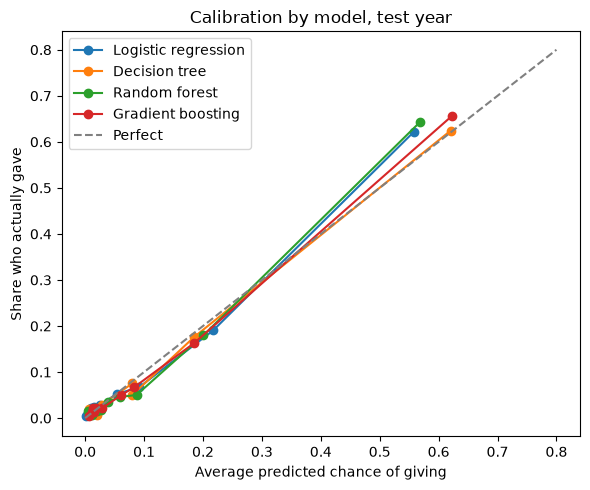

,Brier score (lower is better),improvement over no model
Gradient boosting,0.055,40%
Random forest,0.057,39%
Logistic regression,0.058,37%
Decision tree,0.058,37%
No model: everyone gets 10.3%,0.092,0%


In [11]:
y_test = test.gave_next_fy.astype(int)
dollars = test.next_fy_amount.fillna(0)
test_probs = {kind: m.predict_proba(test[X_cols])[:, 1] for kind, m in models.items()}
p_best = test_probs[best]

fig, ax = plt.subplots(figsize=(6, 5))
for kind, p in test_probs.items():
    calib = pd.DataFrame({"predicted": p, "actual": y_test})
    calib["group"] = pd.qcut(calib.predicted.rank(method="first"), 10, labels=False)
    g10 = calib.groupby("group")[["predicted", "actual"]].mean()
    ax.plot(g10.predicted, g10.actual, marker="o", label=kind)
ax.plot([0, 0.8], [0, 0.8], ls="--", c="grey", label="Perfect")
ax.set(xlabel="Average predicted chance of giving", ylabel="Share who actually gave",
       title="Calibration by model, test year")
ax.legend(); plt.tight_layout(); plt.show()

# Brier score for each model, compared with giving every donor the same average chance
base_rate = y_test.mean()
baseline_brier = brier_score_loss(y_test, np.full(len(y_test), base_rate))
brier = pd.DataFrame({"Brier score (lower is better)":
                      {kind: brier_score_loss(y_test, p) for kind, p in test_probs.items()}})
brier.loc[f"No model: everyone gets {base_rate:.1%}"] = baseline_brier
brier["improvement over no model"] = 1 - brier["Brier score (lower is better)"] / baseline_brier
(brier.sort_values("Brier score (lower is better)")
      .style.format({"Brier score (lower is better)": "{:.3f}", "improvement over no model": "{:.0%}"}))

**How to read this.** Compare each model with the no-model row. All four models score well below it, and their calibration lines sit close to the diagonal. The gaps between models are small, so their percentages are about equally trustworthy. What separates the models is ranking (PR-AUC), not calibration, which is why PR-AUC is the main pick. The main point is that the scores are honest enough to multiply by dollars.


## 6. Test year: FY2025 donors → did they give in FY2026?

Here "solicited" means **mailed**. Donors who aren't mailed aren't dropped; they stay on email if they have a usable address.
The cost cutoff is compared with mailing rules a development office might use instead of a model:
- **Gave in the last 2 years**: roughly the "current + lapsed 1 year" mailing.
- **Gave in the last 5 years**: current donors plus the Lapsed 1 Yr and Lapsed 2–4 Yrs mail segments in `README_generatedata.md`.
- **Mail every mailable donor**: everyone who can receive mail.

Every approach, including the rules, only mails donors who are mailable, so they're compared on the same reachable file. Givers who weren't mailed are split into those still reached by email and those with no usable mail or email.

**Net value** = next-year giving from the donors mailed − the extra cost of mailing them. It's generous, because it credits each gift fully to being on the list, but it's the same yardstick for every approach.


In [12]:
costs = cost_to_solicit(test)

def summarize(name, flagged):
    flagged = np.asarray(flagged).astype(bool)
    return {"approach": name,
            "mailed": flagged.sum(),
            "% of donors mailed": flagged.mean(),
            "recall (givers on mail list)": recall_score(y_test, flagged),
            "precision (mailed who gave)": precision_score(y_test, flagged),
            "givers not mailed: on email": int(((~flagged) & (y_test == 1) & (test.emailable == 1)).sum()),
            "givers not mailed: no mail or email": int(((~flagged) & (y_test == 1) & (test.emailable == 0)).sum()),
            "$ from those mailed": dollars[flagged].sum(),
            "extra mail cost": costs[flagged].sum(),
            "net value": dollars[flagged].sum() - costs[flagged].sum()}

flag_cost = solicit_by_cost(test, p_best)
comparison = pd.DataFrame([
    summarize(f"{kind}: cost cutoff" + (" (chosen)" if kind == best else ""),
              solicit_by_cost(test, p)) for kind, p in test_probs.items()
] + [
    summarize("Rule: gave in last 2 years", (test.years_since_last_gift <= 1) & (test.mailable == 1)),
    summarize("Rule: gave in last 5 years", (test.years_since_last_gift <= 4) & (test.mailable == 1)),
    summarize("Mail every mailable donor", test.mailable == 1),
])
comparison

,approach,mailed,% of donors mailed,recall (givers on mail list),precision (mailed who gave),givers not mailed: on email,givers not mailed: no mail or email,$ from those mailed,extra mail cost,net value
0,Logistic regression: cost cutoff,1980,0.414,0.868,0.216,31,34,"89,835.030","3,481.699","86,353.331"
1,Decision tree: cost cutoff,2081,0.435,0.886,0.210,28,28,"89,818.140","3,636.017","86,182.123"
2,Random forest: cost cutoff,2188,0.457,0.888,0.200,23,32,"90,197.890","3,767.189","86,430.701"
3,Gradient boosting: cost cutoff (chosen),2104,0.440,0.880,0.206,27,32,"89,872.890","3,660.719","86,212.171"
4,Rule: gave in last 2 years,1129,0.236,0.797,0.347,42,58,"82,263.530","2,447.833","79,815.697"
5,Rule: gave in last 5 years,1933,0.404,0.894,0.228,27,25,"89,386.320","3,491.576","85,894.744"
6,Mail every mailable donor,2744,0.574,0.917,0.164,21,20,"90,716.070","4,544.406","86,171.664"


Each model uses the same cost cutoff, so differences come only from how good its probabilities are. The model was chosen on the validation year, before seeing these numbers; if another model wins narrowly here, that's normal year-to-year noise rather than a reason to switch.

How to read this: recall says how many eventual givers each approach puts in the mail; net value says whether mailing them was worth the postage. The cost cutoff can include long-lapsed donors with large past gifts (the 5-year rule never mails them) and leave out low-chance, small-gift donors the rules include.

In [13]:
print(pd.DataFrame(confusion_matrix(y_test, flag_cost),
                   index=["Didn't give", "Gave"], columns=["Not mailed", "Mailed"]))

# Who are the givers the cost cutoff doesn't mail?
missed = test[(y_test == 1) & ~flag_cost]
print(f"\nGivers not mailed: {len(missed)}, who gave ${missed.next_fy_amount.sum():,.0f} in total")
print(missed[["years_since_last_gift", "last_gift_dollars", "tribute_only_as_of_fy_end",
              "mailable", "emailable"]].describe().loc[["mean", "50%"]])

             Not mailed  Mailed
Didn't give        2621    1671
Gave                 59     433

Givers not mailed: 59, who gave $6,902 in total
      years_since_last_gift  last_gift_dollars  tribute_only_as_of_fy_end  \
mean                  3.000            100.949                      0.068   
50%                   3.000             50.420                      0.000   

      mailable  emailable  
mean     0.305      0.458  
50%      0.000      0.000  


## 7. What if asking costs more?

$0.70 a piece is the cheapest case. Real costs can be higher (premiums, a phone call, a second version), and a higher cost should shrink the list. Multiplying the cost shows how sensitive the decision is.

In [14]:
sens = []
for mult in [1, 2, 5, 10, 25]:
    row = summarize(f"cost x {mult}", solicit_by_cost(test, p_best, mult))
    row["cost per donor-year (current / lapsed)"] = f"${annual_cost['Current Donors'] * mult:.2f} / ${annual_cost['Lapsed Donors'] * mult:.2f}"
    sens.append(row)
pd.DataFrame(sens)[["approach", "cost per donor-year (current / lapsed)", "mailed",
                    "recall (givers on mail list)", "givers not mailed: on email", "net value"]]

,approach,cost per donor-year (current / lapsed),mailed,recall (givers on mail list),givers not mailed: on email,net value
0,cost x 1,$2.59 / $1.30,2104,0.880,27,"86,212.171"
1,cost x 2,$5.17 / $2.60,1637,0.829,38,"86,152.138"
2,cost x 5,$12.94 / $6.49,1009,0.699,64,"83,790.529"
3,cost x 10,$25.87 / $12.98,663,0.589,86,"80,771.881"
4,cost x 25,$64.68 / $32.45,343,0.419,120,"71,869.389"


## 8. The trade-off, in pictures

**Left:** a gains chart. Rank donors by score, solicit from the top down, and see what share of next year's givers you've reached. The dot shows where the cost cutoff landed.
**Right:** expected value against cost for each donor. Everyone above the line gets solicited.

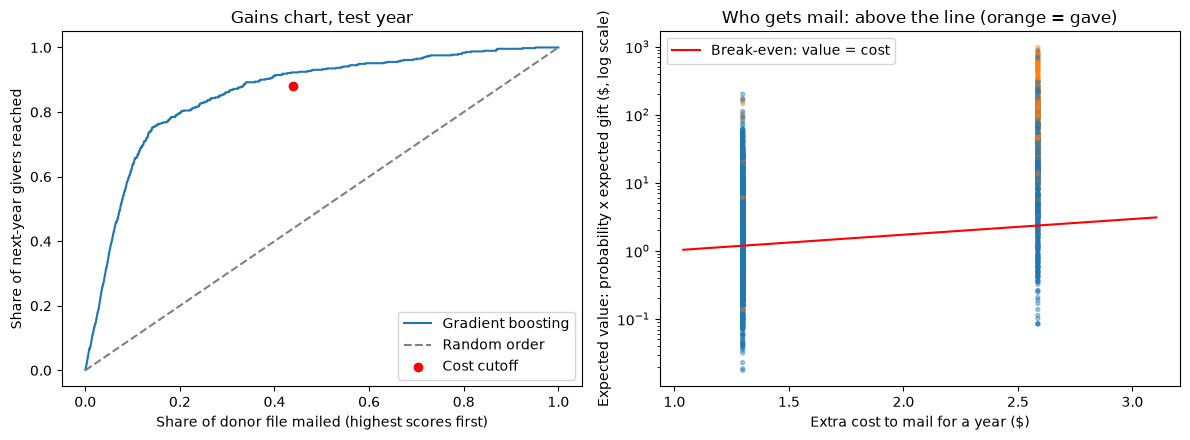

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

order = np.argsort(-p_best)
found = np.cumsum(y_test.values[order]) / y_test.sum()
share = np.arange(1, len(order) + 1) / len(order)
ax[0].plot(share, found, label=best)
ax[0].plot([0, 1], [0, 1], ls="--", c="grey", label="Random order")
ax[0].scatter(flag_cost.mean(), recall_score(y_test, flag_cost), c="red", zorder=3, label="Cost cutoff")
ax[0].set(xlabel="Share of donor file mailed (highest scores first)",
          ylabel="Share of next-year givers reached", title="Gains chart, test year")
ax[0].legend()

ev = p_best * expected_gift(test)
ax[1].scatter(costs, ev, s=8, alpha=0.4, c=np.where(y_test == 1, "tab:orange", "tab:blue"))
lim = [costs.min() * 0.8, costs.max() * 1.2]
ax[1].plot(lim, lim, c="red", label="Break-even: value = cost")
ax[1].set(yscale="log", xlabel="Extra cost to mail for a year ($)",
          ylabel="Expected value: probability x expected gift ($, log scale)",
          title="Who gets mail: above the line (orange = gave)")
ax[1].legend()
plt.tight_layout(); plt.show()

## 9. What drives the predictions?

Permutation importance: shuffle one feature at a time and see how much the model's PR-AUC drops. A bigger drop means the model leans on that feature more.

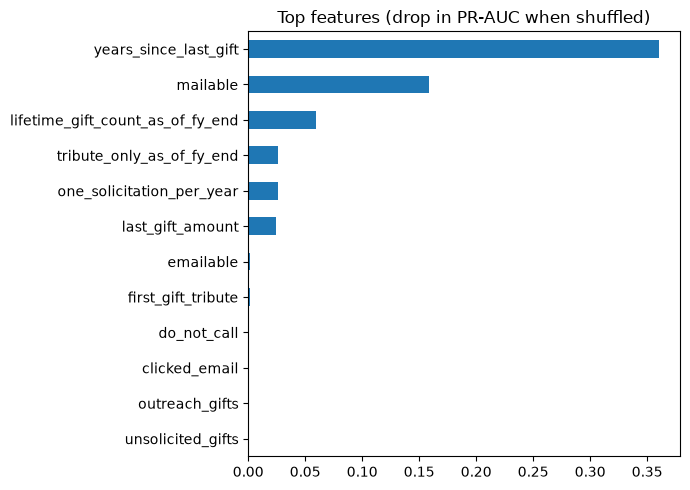

In [16]:
imp = permutation_importance(models[best], test[X_cols], y_test, scoring="average_precision",
                             n_repeats=10, random_state=42)
importance = pd.Series(imp.importances_mean, index=X_cols).sort_values(ascending=False)
importance.head(12).sort_values().plot.barh(figsize=(7, 5), title="Top features (drop in PR-AUC when shuffled)")
plt.tight_layout(); plt.show()

Importance shows *how much* the model relies on a feature, not *which direction* it pushes. The table below adds direction by comparing next-year givers with non-givers in the test year. (Dollar features are on the log scale the model used, so compare them as higher/lower rather than reading them as dollars.)

In [17]:
top = [c for c in importance.index if c in numeric][:10]   # number columns only, so averages make sense
direction = test.groupby(y_test)[list(top)].mean().T
direction.columns = ["avg: didn't give", "avg: gave"]
direction.insert(0, "importance", importance[top])
direction

,importance,avg: didn't give,avg: gave
years_since_last_gift,0.361,4.362,0.750
mailable,0.158,0.534,0.917
lifetime_gift_count_as_of_fy_end,0.059,3.400,4.715
tribute_only_as_of_fy_end,0.026,0.163,0.014
one_solicitation_per_year,0.026,0.101,0.020
last_gift_amount,0.024,4.174,4.482
emailable,0.001,0.354,0.392
first_gift_tribute,0.001,0.195,0.069
do_not_call,0.000,0.097,0.126
unsolicited_gifts,0.000,0.055,0.108


Things to watch for when interpreting this:
- **Contact info matters partly for a mechanical reason.** Someone with no address and no email can't receive most appeals, so they rarely give. That's real and useful for targeting, but it's reachability, not loyalty.
- **Recency now comes from one feature.** With the duplicate this-year fields removed, years since last gift is the model's only direct measure of when someone last gave, so it carries the recency signal on its own instead of splitting credit with other fields. The channel counts (mail, outreach, and unsolicited gifts this year) are still above 0 only for donors who gave this year, so they overlap with recency a little.
- **The data is simulated.** The model can only rediscover the rules in `generate_data.py`. If it ranked something the generator never uses as important, that would signal a bug.

## 10. Next year's channel plan

Score every FY2026 donor with a model refit on all four labeled years, then apply the cost cutoff to choose a channel. Each donor gets one of four recommendations:
- **Mail + email**: above the cutoff and mailable.
- **Email only: find mailing address**: above the cutoff and worth mailing, but no usable address. These are the most valuable contact-info updates.
- **Email only**: below the cutoff, with a usable email.
- **No mail or email: update contact info**: no usable way to reach them. They're flagged rather than dropped, since the only thing keeping them out of the program is missing data. The output includes each donor's expected value, so the team can sort by it or trim from the bottom if the budget is tight.

In [18]:
all_labeled = model_df[model_df.fiscal_year.between(2022, 2025)]
final_model = make_model(best).fit(all_labeled[X_cols], all_labeled.gave_next_fy)

score = score.assign(prob_give_fy2027=final_model.predict_proba(score[X_cols])[:, 1])
score["expected_gift"] = expected_gift(score)
score["expected_value"] = score.prob_give_fy2027 * score.expected_gift
score["cost_to_solicit"] = cost_to_solicit(score)
above = score.expected_value > score.cost_to_solicit
score["recommended_channel"] = np.select(
    [above & (score.mailable == 1),
     above & (score.emailable == 1),
     score.emailable == 1],
    ["Mail + email", "Email only: find mailing address", "Email only"],
    default="No mail or email: update contact info")
out = score[["donor_id", "prob_give_fy2027", "expected_gift", "expected_value", "cost_to_solicit",
             "recommended_channel", "donor_status_fy", "years_since_last_gift", "mailable", "emailable"]
            ].sort_values("expected_value", ascending=False)
out.to_csv("outputs/fy2027_solicitation_scores.csv", index=False)
pd.crosstab(out.donor_status_fy, out.recommended_channel, margins=True)

recommended_channel,Email only,Email only: find mailing address,Mail + email,No mail or email: update contact info,All
donor_status_fy,,,,,
Lapsed,684,329,1385,1894,4292
New,61,21,278,91,451
Reactivated,0,16,77,16,109
Retained,3,8,348,15,374
All,748,374,2088,2016,5226


## Takeaways

The cell below writes up the key results from this run, so the summary and README always match the latest numbers.

**Caveats to state:** net value credits every gift to the mailing, though some donors would have given anyway. The expected gift is a simple estimate based on the last gift. Only direct mail costs are counted: email is close to free, and personal outreach is a separate staffing decision.


In [19]:
from IPython.display import Markdown, display

comp = comparison.set_index("approach")
chosen = comp.loc[[a for a in comp.index if "(chosen)" in a][0]]
rule5 = comp.loc["Rule: gave in last 5 years"]
rule5_flag = ((test.years_since_last_gift <= 4) & (test.mailable == 1)).values
added_long_lapsed = int((flag_cost & ~rule5_flag).sum())
dropped_from_mail = int((rule5_flag & ~flag_cost).sum())
s1, s2 = sens[0], sens[1]
net_gain = chosen["net value"] - rule5["net value"]
cost2_change = s2["net value"] - s1["net value"]

val = pd.DataFrame(results).set_index("model")
simple = "Logistic regression" if best != "Logistic regression" else "Decision tree"
simple_net = comp.loc[[a for a in comp.index if a.startswith(simple)][0], "net value"]
pr_gap = val.loc[best, "validation PR-AUC"] - val.loc[simple, "validation PR-AUC"]
net_gap = simple_net - chosen["net value"]

best_brier = brier.loc[best, "Brier score (lower is better)"]
brier_gain = brier.loc[best, "improvement over no model"]

# Plain-English feature names, and whether givers had more or less of each
labels = {"fy_gift_count": "Number of gifts this year",
          "mailable": "Can be mailed (usable address, no Do Not Mail code)",
          "lifetime_gift_count_as_of_fy_end": "Lifetime number of gifts",
          "tribute_only_as_of_fy_end": "Has only ever made tribute gifts",
          "one_solicitation_per_year": "Has the One Solicitation Per Year code",
          "years_since_last_gift": "Years since last gift",
          "fy_gift_amount": "Amount given this year",
          "last_gift_amount": "Size of last gift",
          "avg_gift": "Average gift size",
          "first_gift_tribute": "First gift was a tribute gift",
          "emailable": "Can be emailed",
          "events_attended_as_of_fy_end": "Events attended",
          "clicked_email": "Clicked an email this year"}
lines = []
for col in importance.index[:5]:
    name = labels.get(col, col.replace("_", " ").capitalize())
    if col in numeric:
        higher = test.loc[y_test == 1, col].mean() > test.loc[y_test == 0, col].mean()
        name += " (higher for givers)" if higher else " (lower for givers)"
    lines.append(f"{len(lines) + 1}. {name}")
predictors = "\n".join(lines)

tie = pr_gap <= 0.01
model_note = (f"That's effectively a tie, so the simpler, easier-to-explain {simple.lower()} is a reasonable choice for a fundraising team."
              if tie else
              f"{best} ranks donors noticeably better, so it stays the recommended model. The test-year difference in net value "
              f"is under 1% of the total, which is normal year-to-year variation."
              if abs(net_gap) < 0.01 * chosen["net value"] else
              f"{best} ranks donors noticeably better on the validation year, so it stays the recommended model.")

display(Markdown(f"""
### What the model delivers (test year: FY2025 donors, FY2026 giving)
- **Mail list:** {chosen['mailed']:,.0f} donors, {chosen['% of donors mailed']:.0%} of the file. Everyone else stays on email if they have an address.
- **Givers reached by mail:** {chosen['recall (givers on mail list)']:.0%} of the donors who gave the next year.
- **Net value:** ${chosen['net value']:,.0f}, compared with ${rule5['net value']:,.0f} for mailing everyone who gave in the last 5 years ({'+' if net_gain >= 0 else '−'}${abs(net_gain):,.0f}).
- **Trustworthy percentages:** Brier score {best_brier:.3f}, {brier_gain:.0%} better than giving every donor the same average chance.

### How it differs from the 5-year rule
- **Adds {added_long_lapsed} long-lapsed donors** (5+ years since their last gift) whose past gifts make them worth mailing.
- **Takes {dropped_from_mail} donors off the mail list** that the rule would mail, because their expected gift doesn't cover the postage.

### How sensitive it is to cost
If mailing cost twice as much, the mail list would shrink by {1 - s2['mailed'] / s1['mailed']:.0%} ({s1['mailed']:,.0f} → {s2['mailed']:,.0f} donors), but net value would {'drop' if cost2_change < 0 else 'rise'} by only ${abs(cost2_change):,.0f}. The size of the list depends on cost; the dollars don't, much.

### What predicts giving again
{predictors}

### Which model to use
{best} ranked donors best on the validation year (PR-AUC {val.loc[best, 'validation PR-AUC']:.3f}). {simple} scored {pr_gap:.3f} lower and earned ${abs(net_gap):,.0f} {'more' if net_gap >= 0 else 'less'} in net value on the test year. {model_note}
"""))



### What the model delivers (test year: FY2025 donors, FY2026 giving)
- **Mail list:** 2,104 donors, 44% of the file. Everyone else stays on email if they have an address.
- **Givers reached by mail:** 88% of the donors who gave the next year.
- **Net value:** $86,212, compared with $85,895 for mailing everyone who gave in the last 5 years (+$317).
- **Trustworthy percentages:** Brier score 0.055, 40% better than giving every donor the same average chance.

### How it differs from the 5-year rule
- **Adds 361 long-lapsed donors** (5+ years since their last gift) whose past gifts make them worth mailing.
- **Takes 190 donors off the mail list** that the rule would mail, because their expected gift doesn't cover the postage.

### How sensitive it is to cost
If mailing cost twice as much, the mail list would shrink by 22% (2,104 → 1,637 donors), but net value would drop by only $60. The size of the list depends on cost; the dollars don't, much.

### What predicts giving again
1. Years since last gift (lower for givers)
2. Can be mailed (usable address, no Do Not Mail code) (higher for givers)
3. Lifetime number of gifts (higher for givers)
4. Has only ever made tribute gifts (lower for givers)
5. Has the One Solicitation Per Year code (lower for givers)

### Which model to use
Gradient boosting ranked donors best on the validation year (PR-AUC 0.605). Logistic regression scored 0.038 lower and earned $141 more in net value on the test year. Gradient boosting ranks donors noticeably better, so it stays the recommended model. The test-year difference in net value is under 1% of the total, which is normal year-to-year variation.
